In [ ]:
import pandas as pd
import requests
import io
import matplotlib.pyplot as plt


In [ ]:
# =========================================================
# ATIVIDADE PRÁTICA 3
# Garimpo e Diagnóstico de Dados de Saúde - DataSUS
# Dataset: RIPSA Morbidade
# =========================================================

url = "https://demas-dados-abertos.s3.amazonaws.com/csv/ripsa001mb.csv.zip"

df = pd.read_csv(url, encoding='utf-8')

# Visualizar
print(df.head())

# Informações gerais
print("\nInformações gerais:")
print(df.info())
print(df.dtypes)
print(df.shape) # Quantidade de linhas e colunas



   co_anomes  co_ibge  vl_indicador_calculado_mun  co_uf  \
0     201312   352630                         0.0     35   
1     202112   354680                         1.0     35   
2     201912   292275                         0.0     29   
3     201512   430222                         0.0     43   
4     201212   314100                         0.0     31   

           no_municipio sg_uf              no_uf  co_regiao_brasil  \
0              Lagoinha    SP          São Paulo                 3   
1          Santa Isabel    SP          São Paulo                 3   
2             Nova Ibiá    BA              Bahia                 2   
3  Boa Vista do Cadeado    RS  Rio Grande do Sul                 4   
4            Mato Verde    MG       Minas Gerais                 3   

  no_regiao_brasil sg_regiao_brasil  ...  vl_indicador_calculado_al  \
0          Sudeste               SE  ...                        0.0   
1          Sudeste               SE  ...                        0.0   
2    

In [ ]:

# 4. CONVERSÃO DE DATAS

df['dt_competencia'] = pd.to_datetime(
    df['dt_competencia'],
    errors='coerce'
)

df['dt_atualizacao'] = pd.to_datetime(
    df['dt_atualizacao'],
    errors='coerce'
)

print("\nTipos após conversão:")
print(df[['dt_competencia', 'dt_atualizacao']].dtypes)

# 5. DADOS AUSENTES
# Quantidade de nulos
print("\nQuantidade de valores nulos:")
print(df.isnull().sum())

# Percentual de nulos
print("\nPercentual de valores nulos:")
print((df.isnull().sum() / len(df)) * 100)

# Tabela organizada
nulos = pd.DataFrame({
    'Qtd_Nulos': df.isnull().sum(),
    'Percentual (%)': (df.isnull().sum() / len(df)) * 100
})

nulos = nulos.sort_values(
    by='Percentual (%)',
    ascending=False
)

print("\nTabela de dados ausentes:")
print(nulos)

# 6. DUPLICIDADES
duplicados = df.duplicated().sum()

print(f"\nQuantidade de registros duplicados: {duplicados}")

# Mostrar duplicados caso existam
if duplicados > 0:
    print("\nExemplo de registros duplicados:")
    print(df[df.duplicated()].head())

# 7. ESTATÍSTICAS DESCRITIVAS
print("ESTATÍSTICAS DESCRITIVAS")
print(df.describe())

# 8. VERIFICAÇÃO DE ANOMALIAS
print("ANÁLISE DE ANOMALIAS")

# Verificar anos existentes
print("\nAnos existentes na base:")

anos = (
    df['co_anomes']
    .astype(str)
    .str[:4]
    .value_counts()
    .sort_index()
)

print(anos)

# Estados existentes
print("\nEstados presentes na base:")
print(df['sg_uf'].value_counts())

# Categorias existentes
print("\nCategorias existentes:")
print(df['ds_categoria'].value_counts())

# 9. DICIONÁRIO BÁSICO DAS VARIÁVEIS
print("DICIONÁRIO DAS PRINCIPAIS COLUNAS")

dicionario = {
    'co_anomes': 'Ano e mês do registro',
    'co_ibge': 'Código IBGE do município',
    'no_municipio': 'Nome do município',
    'co_uf': 'Código da unidade federativa',
    'sg_uf': 'Sigla do estado',
    'no_uf': 'Nome do estado',
    'co_regiao_brasil': 'Código da região do Brasil',
    'no_regiao_brasil': 'Nome da região',
    'vl_indicador_calculado_mun': 'Indicador calculado para município',
    'dt_competencia': 'Data de competência',
    'dt_atualizacao': 'Data da última atualização'
}

for chave, valor in dicionario.items():
    print(f"{chave} -> {valor}")



Tipos após conversão:
dt_competencia    datetime64[ns]
dt_atualizacao    datetime64[ns]
dtype: object

Quantidade de valores nulos:
co_anomes                          0
co_ibge                            0
vl_indicador_calculado_mun         0
co_uf                              0
no_municipio                       0
sg_uf                              0
no_uf                              0
co_regiao_brasil                   0
no_regiao_brasil                   0
sg_regiao_brasil                   0
co_regiao_saude                    0
no_regiao_saude                    0
no_macro                           0
co_macro                           0
vl_indicador_calculado_rs          0
vl_indicador_calculado_ms          0
vl_indicador_calculado_uf          0
vl_indicador_calculado_reg         0
vl_indicador_calculado_br          0
vl_indicador_calculado_al          0
dt_competencia                     0
dt_atualizacao                     0
ds_unidade_medida                  0
sg_granularidade

                   no_municipio sg_uf
167023                    Arara    PB
171253                    Arari    MA
203598                Araripina    PE
203758                   Gararu    SE
203844                  Guarará    MG
203991       Cachoeira do Arari    PA
402338                 Ararendá    CE
402392                  Araruna    PB
403721      Santa Cruz do Arari    PA
404050                  Itararé    SP
404232                  Araruna    PR
404900                   Araras    SP
404958         Salto do Itararé    PR
406146  Jaboatão dos Guararapes    PE
406560                Jaguarari    BA
406607               Guararapes    SP
406654                Araranguá    SC
407827   Bom Sucesso de Itararé    SP
408173                   Parari    PB
408232                  Araripe    CE
409671               Araraquara    SP
422786                 Araruama    RJ
422907                Guararema    SP
426104       Santana do Itararé    PR
448709                  Araricá    RS
(3835, 30)



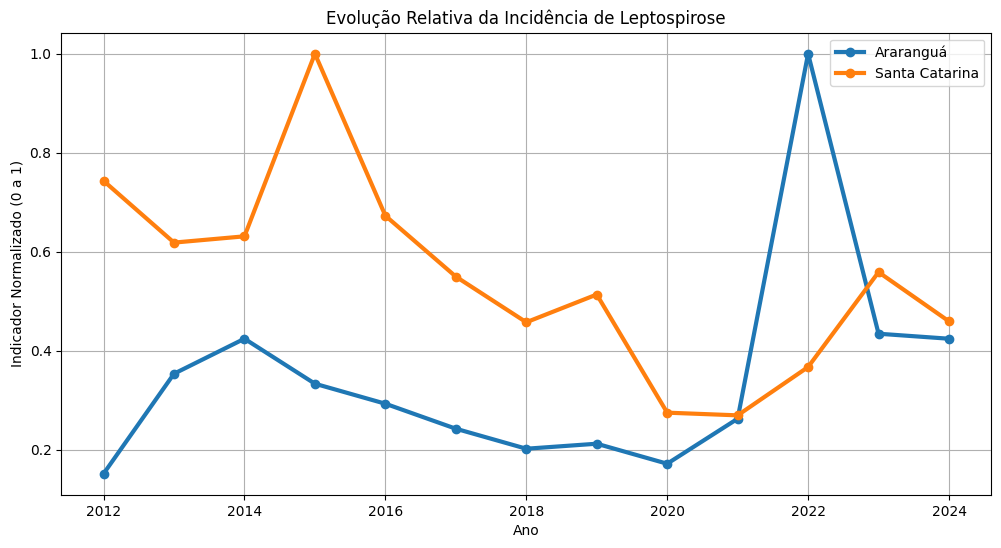

In [ ]:

# FILTRAR "TODAS AS CATEGORIAS"

df_total = df[
    df['ds_categoria'] == 'Todas as categorias'
].copy()


df_total['ano'] = df_total['dt_competencia'].dt.year

# FILTRAR ARARANGUÁ
df_ararangua = df_total[
    df_total['no_municipio']
    .str.contains('Arar', case=False, na=False)
].copy()

print(df_ararangua[['no_municipio', 'sg_uf']].drop_duplicates())

# FILTRAR SANTA CATARINA
df_sc = df_total[
    df_total['sg_uf'] == 'SC'
].copy()

print(df_sc.shape)

# AGRUPAR DADOS
# Araranguá
ararangua_ano = (
    df_ararangua
    .groupby('ano')['vl_indicador_calculado_mun']
    .mean()
)

# Santa Catarina
sc_ano = (
    df_sc
    .groupby('ano')['vl_indicador_calculado_uf']
    .mean()
)

print("\nAraranguá:")
print(ararangua_ano)

print("\nSanta Catarina:")
print(sc_ano)

# NORMALIZAR OS DADOS
# Evita divisão por zero
ararangua_norm = (
    ararangua_ano / ararangua_ano.max()
)

sc_norm = (
    sc_ano / sc_ano.max()
)

# GRÁFICO NORMALIZADO
plt.figure(figsize=(12,6))

plt.plot(
    ararangua_norm.index,
    ararangua_norm.values,
    marker='o',
    linewidth=3,
    label='Araranguá'
)

plt.plot(
    sc_norm.index,
    sc_norm.values,
    marker='o',
    linewidth=3,
    label='Santa Catarina'
)

plt.title('Evolução Relativa da Incidência de Leptospirose')

plt.xlabel('Ano')
plt.ylabel('Indicador Normalizado (0 a 1)')

plt.legend()

plt.grid(True)

plt.show()

## Diagnóstico da Base de Dados

A base escolhida foi o indicador MRB.1.15 – Incidência de leptospirose, disponibilizado pelo DataSUS/RIPSA. O consumo dos dados foi realizado diretamente via URL utilizando Python e a biblioteca Pandas, sem necessidade de download manual do arquivo.

Durante a análise exploratória, observou-se que a base possui boa estrutura geral, contendo mais de 539 mil registros e 29 variáveis. A maior parte das colunas apresentou preenchimento consistente, porém foram identificados alguns problemas que exigem tratamento antes de análises mais avançadas.

As principais necessidades de limpeza encontradas foram:

* conversão de colunas de data que estavam armazenadas como texto;
* presença de valores ausentes em algumas variáveis categóricas;
* necessidade de interpretação de códigos administrativos e epidemiológicos do DataSUS;
* padronização e entendimento das categorias utilizadas na base.

Também foram realizadas verificações de duplicidade, análise de tipos de dados, identificação de categorias existentes e exploração temporal dos registros.

De forma geral, a base não necessita de uma “faxina pesada”, mas sim de um tratamento moderado para preparação dos dados. Após as etapas de limpeza e organização, os dados mostraram-se adequados para análises epidemiológicas e comparações entre municípios e estados, como a análise da incidência de leptospirose entre Araranguá e Santa Catarina.
